# 学会で有名になる戦略: シミュレーション

有名さをネットワークの中心性と定義し、3つの戦略(知り合い・研究・アウトリーチ)への資源配分を探ります。
モデルの詳細は `DESIGN.md` を参照してください。

- モデル1: 全員がランダムな配分で固定
- モデル2: 自分だけ学習
- モデル3: 全員が学習

`SMALL = True` なら少数シードで数十秒、`False` なら本番設定で数分かかります。

In [1]:
import sys, os, json
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

sys.path.insert(0, os.path.abspath('../src'))
from sim import DEFAULT, Sim, model1, model2, model3, power

SMALL = True                      # False にすると本番設定
N_SEED_M1 = 8  if SMALL else 20   # モデル1のシード数
N_SEED_M2 = 4  if SMALL else 16   # モデル2のシード数
N_SEED_M3 = 2  if SMALL else 8    # モデル3のシード数
T_LEARN   = 3000                  # モデル2は学習に時間がかかるので長く回す
T_M3      = 12000                 # モデル3(模倣学習)は集団がまとまるまでさらに長くかかる

p = dict(DEFAULT)                 # ここを書き換えればパラメータを変えられる
pool = lambda: ProcessPoolExecutor(mp_context=mp.get_context('fork'))
print(p)

{'N': 200, 'K': 5, 'R': 1.0, 'T': 600, 'mu': 0.02, 'delta': 0.05, 'a1': 0.08, 'K1': 2.0, 'a2': 0.004, 'a3': 0.12, 'K3': 14.0, 'n3': 6, 'm0': 2, 'replace': True, 'tau': 50, 'eta': 0.05, 'measure': 'degree', 'beta': 0.3, 'learning': 'hill', 'imit_K': 0.5, 'mut_rate': 0.1, 'mut_sigma': 0.15}


## 1. 張る力の関数形

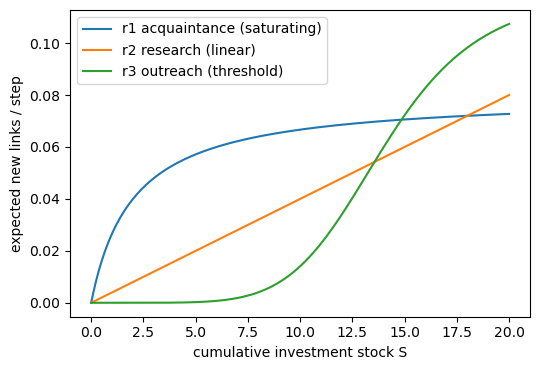

In [2]:
S = np.linspace(0, p['R'] / p['delta'], 200)
f = power(np.stack([S, S, S], 1), p)
plt.figure(figsize=(5.5, 3.8))
for k, n in enumerate(['r1 acquaintance (saturating)', 'r2 research (linear)', 'r3 outreach (threshold)']):
    plt.plot(S, f[:, k], label=n)
plt.xlabel('cumulative investment stock S'); plt.ylabel('expected new links / step')
plt.legend(); plt.tight_layout(); plt.show()

## 2. モデル1: ランダム配分で固定

配分を三角図(左下=知り合い、右下=研究、上=アウトリーチ)に置き、色で有名さ(1回の中での順位パーセンタイル)を表します。

In [3]:
def _m1(s): return model1(DEFAULT, s)

with pool() as ex:
    res1 = list(ex.map(_m1, range(N_SEED_M1)))

rank = lambda v: v.argsort().argsort() / (len(v) - 1)
X  = np.concatenate([r['x'] for r in res1])
D  = np.concatenate([rank(r['deg']) for r in res1])
PR = np.concatenate([rank(r['pr'])  for r in res1])
B  = np.concatenate([rank(r['btw']) for r in res1])
print('samples:', len(X))

samples: 1600


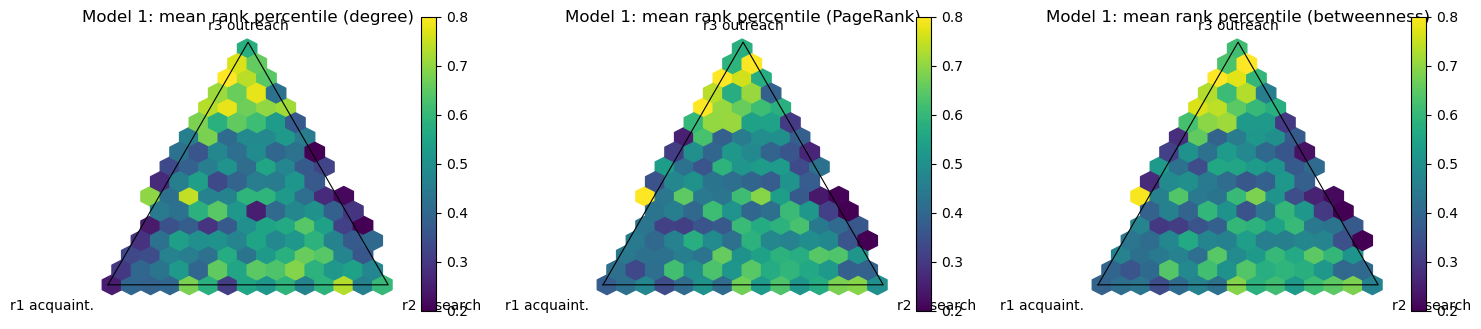

top 5% mean allocation (degree): [0.251 0.318 0.431]
top 5% mean allocation (pagerank): [0.3   0.284 0.416]
top 5% mean allocation (betweenness): [0.303 0.301 0.395]


In [4]:
def tern(x):
    return x[:, 1] + 0.5 * x[:, 2], np.sqrt(3) / 2 * x[:, 2]

# モデル2の軌跡図で使う頂点ラベルの色と大きさ
M2_LABEL_COLORS = {'acquaint': 'tab:blue', 'research': 'tab:orange', 'outreach': 'tab:green'}
M2_LABEL_SIZE = 16

def tri_axes(ax, title, label_colors=None, fontsize=None):
    """三角図の枠と頂点ラベル。label_colors と fontsize を省略すると黒の既定サイズ"""
    lc = label_colors or {}
    kw = dict(fontsize=fontsize) if fontsize else {}
    ax.plot([0, 1, 0.5, 0], [0, 0, np.sqrt(3)/2, 0], 'k-', lw=0.8)
    ax.text(-0.05, -0.05, 'r1 acquaint.', ha='right', va='top', color=lc.get('acquaint', 'k'), **kw)
    ax.text(1.05, -0.05, 'r2 research', ha='left', va='top', color=lc.get('research', 'k'), **kw)
    ax.text(0.5, 0.9, 'r3 outreach', ha='center', va='bottom', color=lc.get('outreach', 'k'), **kw)
    ax.set_title(title, **kw)
    ax.set_aspect('equal'); ax.axis('off')

fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, v, n in zip(axs, (D, PR, B), ('degree', 'PageRank', 'betweenness')):
    u, w = tern(X)
    hb = ax.hexbin(u, w, C=v, gridsize=14, cmap='viridis', reduce_C_function=np.mean, vmin=0.2, vmax=0.8)
    tri_axes(ax, f'Model 1: mean rank percentile ({n})'); fig.colorbar(hb, ax=ax, shrink=0.7)
plt.tight_layout(); plt.show()

for v, n in ((D, 'degree'), (PR, 'pagerank'), (B, 'betweenness')):
    top = v >= np.quantile(v, 0.95)
    print(f'top 5% mean allocation ({n}):', X[top].mean(0).round(3))

## 3. モデル2とモデル3: 学習

- **モデル2**: ノード0だけが自分の試行錯誤(山登り)で学習します。初期値は均等配分です。
- **モデル3**: 全員が隣人の模倣で学習します。評価窓ごとに隣人を1人選び、相手の成績が良いほど高い確率でその配分をまねます(フェルミ則)。全員が同じ均等配分から始めるので、まれに配分が少しずれる突然変異で新しい戦略を試します。

In [5]:
def _m2(s):
    traj, sim = model2(dict(DEFAULT, T=T_LEARN), 100 + s); return traj, sim
def _m3(s):
    hist, sim = model3(dict(DEFAULT, T=T_M3), 200 + s); return hist, sim

with pool() as ex:
    f2 = [ex.submit(_m2, s) for s in range(N_SEED_M2)]
    f3 = [ex.submit(_m3, s) for s in range(N_SEED_M3)]
    res2 = [f.result() for f in f2]
    res3 = [f.result() for f in f3]
print('done')

done


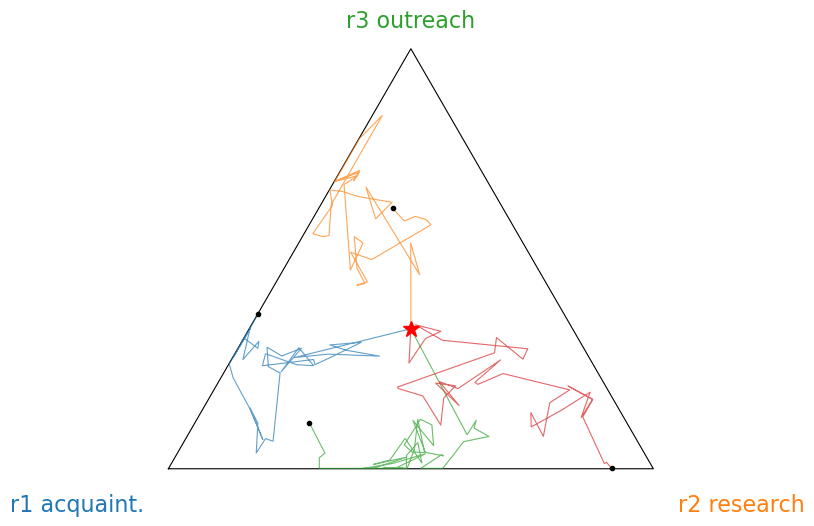

final allocation mean (model 2): [0.399 0.326 0.275]


In [6]:
fig, ax = plt.subplots(figsize=(7, 6)); tri_axes(ax, '', M2_LABEL_COLORS, M2_LABEL_SIZE)
finals = []
for traj, _ in res2:
    u, w = tern(traj); ax.plot(u, w, '-', lw=0.8, alpha=0.7); ax.plot(u[-1], w[-1], 'ko', ms=3)
    finals.append(traj[-1])
ax.plot(*tern(np.array([[1/3, 1/3, 1/3]])), 'r*', ms=12)
plt.show()
print('final allocation mean (model 2):', np.mean(finals, 0).round(3))

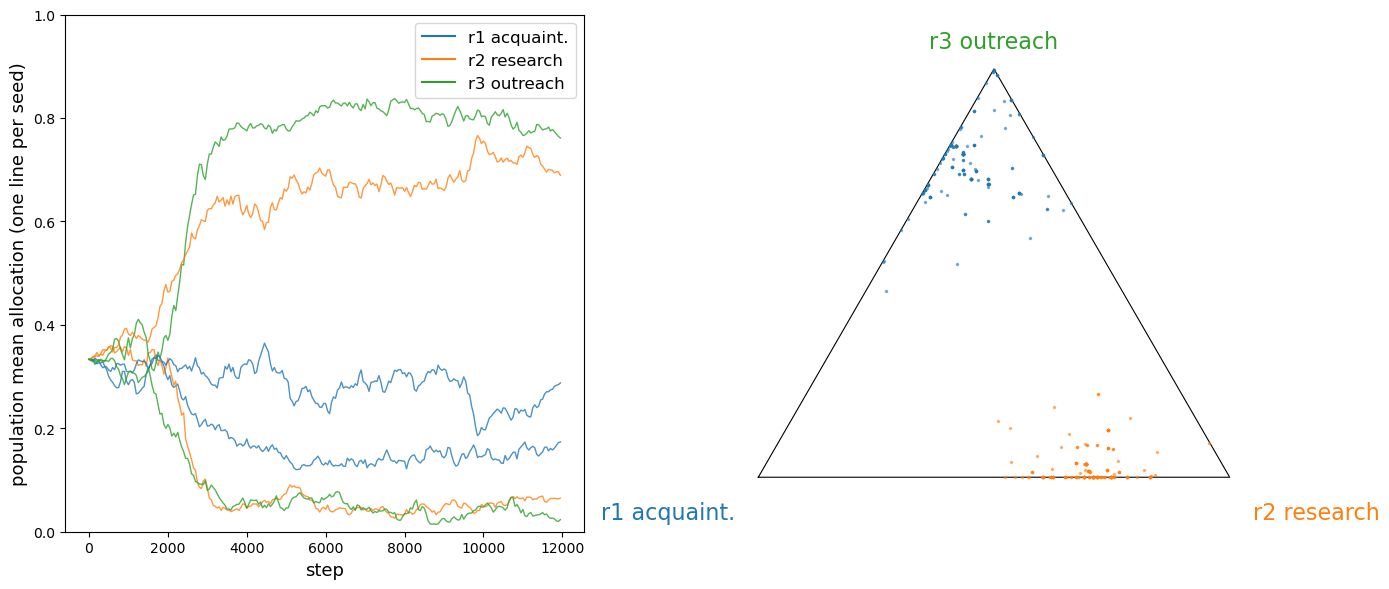

seed 0: final population mean allocation [0.17 0.06 0.77]
seed 1: final population mean allocation [0.29 0.69 0.02]


In [7]:
H3 = [h.mean(1) for h, _ in res3]      # シードごとの集団平均の推移
X3 = [s.x for _, s in res3]             # シードごとの最終配分
# シードごとに行き先が分かれるので、シードをまたいで平均しない
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
t = np.arange(len(H3[0])) * p['tau']
for h in H3:
    for k, key in enumerate(['acquaint', 'research', 'outreach']):
        axs[0].plot(t, h[:, k], color=M2_LABEL_COLORS[key], lw=1, alpha=0.8)
from matplotlib.lines import Line2D
axs[0].legend(handles=[Line2D([], [], color=M2_LABEL_COLORS[k], label=n) for k, n in
                       (('acquaint', 'r1 acquaint.'), ('research', 'r2 research'), ('outreach', 'r3 outreach'))],
              fontsize=12)
axs[0].set_ylim(0, 1); axs[0].set_xlabel('step', fontsize=13)
axs[0].set_ylabel('population mean allocation (one line per seed)', fontsize=13)
tri_axes(axs[1], '', M2_LABEL_COLORS, M2_LABEL_SIZE)
for j, x in enumerate(X3):
    axs[1].plot(*tern(x), '.', color=plt.cm.tab10(j % 10), ms=3, alpha=0.5)
plt.tight_layout(); plt.show()
for j, x in enumerate(X3):
    print(f'seed {j}: final population mean allocation', x.mean(0).round(2))

## 4. 最終状態のネットワーク

ノードの大きさは次数、色は最も配分が大きい戦略、黒い輪は次数上位5人です。モデル2では学習者に太い輪を付けます。

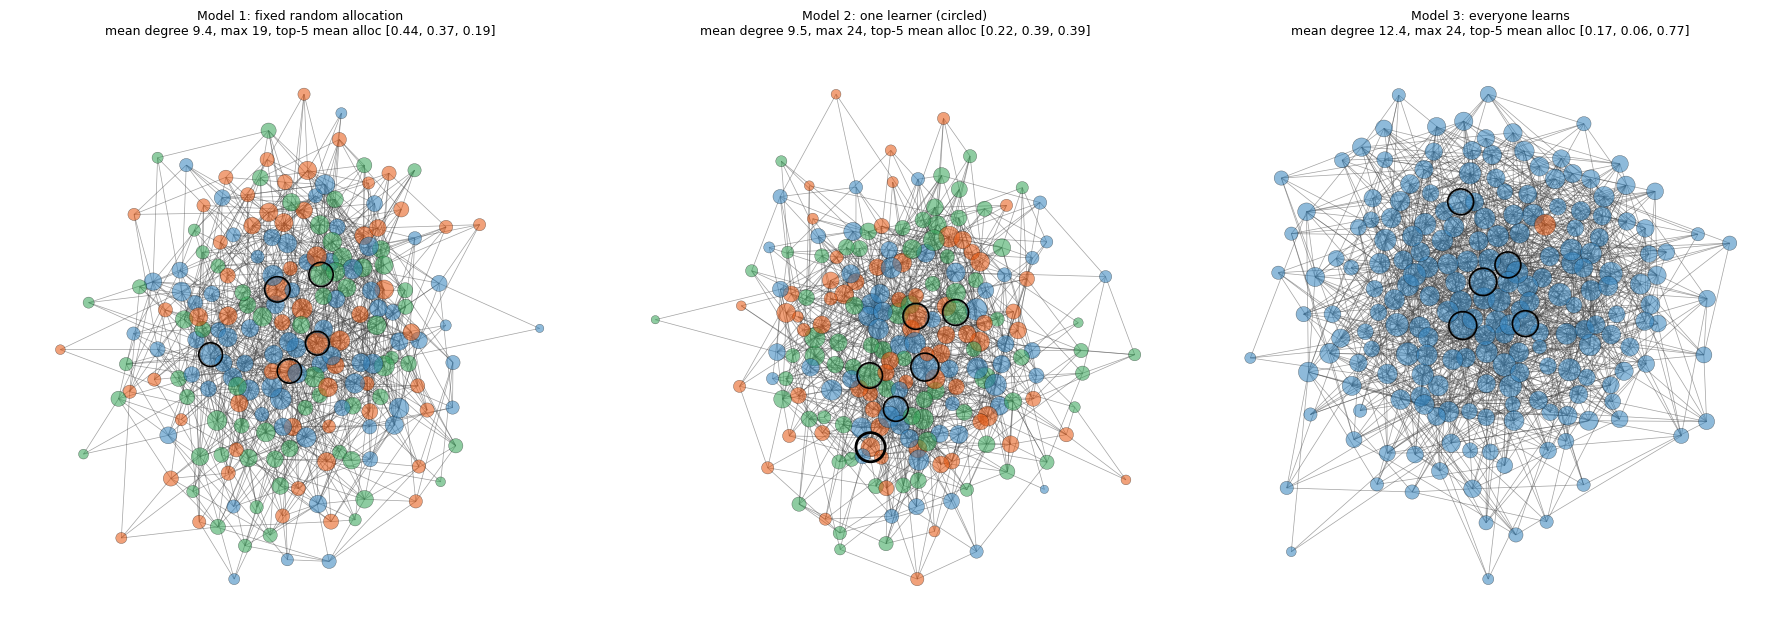

In [8]:
COLORS = ['#e6550d', '#31a354', '#3182bd']   # 知り合い / 研究 / アウトリーチ

def draw(ax, sim, title, focal=None):
    n = sim.p['N']
    G = nx.Graph(); G.add_nodes_from(range(n))
    G.add_edges_from((i, j) for i in range(n) for j in sim.adj[i] if i < j)
    pos = nx.spring_layout(G, seed=0, k=1.2 / np.sqrt(n), iterations=200)
    deg = np.array([G.degree(i) for i in G])
    nx.draw_networkx_edges(G, pos, ax=ax, width=0.5, alpha=0.5, edge_color='#444444')
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=8 + 14 * deg,
                           node_color=[COLORS[k] for k in sim.x.argmax(1)],
                           linewidths=0.3, edgecolors='k', alpha=0.55)
    top = np.argsort(-deg)[:5]
    ax.scatter(*np.array([pos[i] for i in top]).T, s=8 + 14 * deg[top] + 60,
               facecolors='none', edgecolors='k', linewidths=1.2, zorder=4)
    if focal is not None:
        ax.scatter(*pos[focal], s=8 + 14 * deg[focal] + 250, facecolors='none',
                   edgecolors='k', linewidths=2, zorder=5)
    ax.set_title(f'{title}\nmean degree {deg.mean():.1f}, max {deg.max()}, '
                 f'top-5 mean alloc {np.round(sim.x[top].mean(0), 2).tolist()}', fontsize=9)
    ax.axis('off')

# モデル1は1回分をここで回す
rng = np.random.default_rng(0)
sim1 = Sim(rng.dirichlet([1, 1, 1], size=p['N']), np.zeros(p['N'], bool), p, rng); sim1.run()

fig, axs = plt.subplots(1, 3, figsize=(18, 6.5))
draw(axs[0], sim1, 'Model 1: fixed random allocation')
draw(axs[1], res2[0][1], 'Model 2: one learner (circled)', focal=0)
draw(axs[2], res3[0][1], 'Model 3: everyone learns')
plt.tight_layout(); plt.show()

## メモ

- 1回のネットワーク図は、1つのシードの結果にすぎません。傾向の根拠には、モデル1の三角図のような複数シードの集計を使ってください。
- 並列実行は `fork` を使うため、Linux と macOS で動きます。Windows では WSL で実行してください。